In [1]:
import numpy as np
import pandas as pd

from sklearn.linear_model import Lasso
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import GridSearchCV

In [2]:
rv_df = pd.read_csv(
    r"C:\Users\maria\Project\HAR-RV\data\usdchf_daily_realized_volatility.csv",
    parse_dates=["trading_date"]
)

In [3]:
rv_df.tail()

,trading_date,RV_fast,RV_slow,IV_TS,RV
1165,2026-06-25,1.406106e-05,1.867974e-05,1.727384e-05,0.004156
1166,2026-06-26,1.087954e-05,1.573885e-05,1.465105e-05,0.003828
1167,2026-06-29,7.859088e-06,9.494561e-06,8.708809e-06,0.002951
1168,2026-06-30,2.267291e-05,1.456705e-05,1.230014e-05,0.003507
1169,2026-07-01,2.143990e-07,2.645313e-07,2.432720e-07,0.000493


In [4]:
p = 100

lasso_df = (
    rv_df[["trading_date", "RV"]]
    .copy()
    .sort_values("trading_date")
    .reset_index(drop=True)
)

# RV_lag_1 is today's RV, used to forecast the next trading day's RV.
for lag in range(1, p + 1):
    lasso_df[f"RV_lag_{lag}"] = lasso_df["RV"].shift(lag - 1)

lasso_df["RV_next"] = lasso_df["RV"].shift(-1)

lasso_df = lasso_df.dropna().reset_index(drop=True)

lasso_df

C:\Users\maria\AppData\Local\Temp\ipykernel_12432\967096486.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  lasso_df[f"RV_lag_{lag}"] = lasso_df["RV"].shift(lag - 1)
C:\Users\maria\AppData\Local\Temp\ipykernel_12432\967096486.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  lasso_df[f"RV_lag_{lag}"] = lasso_df["RV"].shift(lag - 1)
C:\Users\maria\AppData\Local\Temp\ipykernel_12432\967096486.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which h

,trading_date,RV,RV_lag_1,RV_lag_2,RV_lag_3,RV_lag_4,RV_lag_5,RV_lag_6,RV_lag_7,RV_lag_8,...,RV_lag_92,RV_lag_93,RV_lag_94,RV_lag_95,RV_lag_96,RV_lag_97,RV_lag_98,RV_lag_99,RV_lag_100,RV_next
0,2022-05-20,0.005556,0.005556,0.005687,0.005402,0.004984,0.004069,0.005208,0.005799,0.009394,...,0.004108,0.003821,0.003783,0.004341,0.003976,0.004028,0.004058,0.003982,0.004128,0.005897
1,2022-05-23,0.005897,0.005897,0.005556,0.005687,0.005402,0.004984,0.004069,0.005208,0.005799,...,0.003967,0.004108,0.003821,0.003783,0.004341,0.003976,0.004028,0.004058,0.003982,0.005028
2,2022-05-24,0.005028,0.005028,0.005897,0.005556,0.005687,0.005402,0.004984,0.004069,0.005208,...,0.003297,0.003967,0.004108,0.003821,0.003783,0.004341,0.003976,0.004028,0.004058,0.004777
3,2022-05-25,0.004777,0.004777,0.005028,0.005897,0.005556,0.005687,0.005402,0.004984,0.004069,...,0.003790,0.003297,0.003967,0.004108,0.003821,0.003783,0.004341,0.003976,0.004028,0.004747
4,2022-05-26,0.004747,0.004747,0.004777,0.005028,0.005897,0.005556,0.005687,0.005402,0.004984,...,0.003611,0.003790,0.003297,0.003967,0.004108,0.003821,0.003783,0.004341,0.003976,0.004824
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1065,2026-06-24,0.003825,0.003825,0.003495,0.004032,0.003263,0.005132,0.005093,0.002933,0.003361,...,0.003900,0.003181,0.004630,0.005304,0.007182,0.004463,0.004833,0.003633,0.004863,0.004156
1066,2026-06-25,0.004156,0.004156,0.003825,0.003495,0.004032,0.003263,0.005132,0.005093,0.002933,...,0.003696,0.003900,0.003181,0.004630,0.005304,0.007182,0.004463,0.004833,0.003633,0.003828
1067,2026-06-26,0.003828,0.003828,0.004156,0.003825,0.003495,0.004032,0.003263,0.005132,0.005093,...,0.003814,0.003696,0.003900,0.003181,0.004630,0.005304,0.007182,0.004463,0.004833,0.002951
1068,2026-06-29,0.002951,0.002951,0.003828,0.004156,0.003825,0.003495,0.004032,0.003263,0.005132,...,0.004827,0.003814,0.003696,0.003900,0.003181,0.004630,0.005304,0.007182,0.004463,0.003507


In [5]:
feature_cols = [f"RV_lag_{lag}" for lag in range(1, p + 1)]

X_lasso = lasso_df[feature_cols]
y_lasso = lasso_df["RV_next"]

test_size = int(len(lasso_df) * 0.20)
split_index = len(lasso_df) - test_size

X_train = X_lasso.iloc[:split_index]
y_train = y_lasso.iloc[:split_index]

X_test = X_lasso.iloc[split_index:]
y_test = y_lasso.iloc[split_index:]

tscv = TimeSeriesSplit(n_splits=5)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

Training observations: 856
Test observations: 214


In [6]:
lasso_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=100_000))
])

# Candidate lambda values; scikit-learn calls lambda "alpha"
lambda_grid = np.logspace(-10, -3, 100)

grid_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"lasso__alpha": lambda_grid},
    scoring="neg_mean_squared_error",
    cv=tscv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_lambda = grid_search.best_params_["lasso__alpha"]
best_cv_rmse = np.sqrt(-grid_search.best_score_)

print("Best lambda:", best_lambda)
print("Cross-validation RMSE:", best_cv_rmse)

Best lambda: 0.00014174741629268049
Cross-validation RMSE: 0.0012912507144144745


In [7]:
final_lasso_model = grid_search.best_estimator_

beta_hat_lasso = final_lasso_model.named_steps["lasso"].coef_
intercept_hat = final_lasso_model.named_steps["lasso"].intercept_


lasso_coefficients = pd.DataFrame({
    "predictor": feature_cols,
    "beta_hat": beta_hat_lasso
})

lasso_coefficients

,predictor,beta_hat
0,RV_lag_1,0.000637
1,RV_lag_2,0.000173
2,RV_lag_3,0.000065
3,RV_lag_4,0.000051
4,RV_lag_5,0.000083
...,...,...
95,RV_lag_96,0.000000
96,RV_lag_97,-0.000000
97,RV_lag_98,0.000000
98,RV_lag_99,0.000000


In [8]:
nonzero_coefficients = lasso_coefficients[
    lasso_coefficients["beta_hat"] != 0
]

nonzero_coefficients

,predictor,beta_hat
0,RV_lag_1,0.000637
1,RV_lag_2,0.000173
2,RV_lag_3,0.000065
3,RV_lag_4,0.000051
4,RV_lag_5,0.000083
13,RV_lag_14,0.000032
19,RV_lag_20,0.000084


In [9]:
test_forecast = final_lasso_model.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, test_forecast))
test_mae = mean_absolute_error(y_test, test_forecast)

test_results = lasso_df.loc[X_test.index, ["trading_date", "RV_next"]].copy()
test_results["RV_forecast"] = test_forecast
test_results["forecast_error"] = (
    test_results["RV_next"] - test_results["RV_forecast"]
)

print("Test RMSE:", test_rmse)
print("Test MAE:", test_mae)

test_results

Test RMSE: 0.0008913547573713041
Test MAE: 0.0006920163824301924


,trading_date,RV_next,RV_forecast,forecast_error
856,2025-09-03,0.003865,0.004350,-0.000484
857,2025-09-04,0.004903,0.004197,0.000706
858,2025-09-05,0.003710,0.004554,-0.000843
859,2025-09-08,0.004522,0.004362,0.000160
860,2025-09-09,0.004618,0.004540,0.000079
...,...,...,...,...
1065,2026-06-24,0.004156,0.004179,-0.000023
1066,2026-06-25,0.003828,0.004252,-0.000424
1067,2026-06-26,0.002951,0.004182,-0.001231
1068,2026-06-29,0.003507,0.003776,-0.000268


## Compare forecasts on the common test set

The HAR and AR(22) coefficients in `setup.ipynb` were estimated on the full sample. For this out-of-sample comparison, estimate both models again using only the same training observations as LASSO, then freeze their coefficients.

Here, `RV_lag_1` is today's RV. HAR uses that value and the averages of lags 1-5 and 1-22; AR(22) uses lags 1-22 separately, corresponding to lags 0-21 in the setup notebook. All four models predict the next trading day's RV on exactly the same test rows. Observed RV becomes available as the test period advances, so these are successive one-day-ahead forecasts.

In [10]:
import statsmodels.api as sm

ar22_feature_cols = [f"RV_lag_{lag}" for lag in range(1, 23)]
weekly_feature_cols = [f"RV_lag_{lag}" for lag in range(1, 6)]

har_predictors = pd.DataFrame({
    "RV_d": X_lasso["RV_lag_1"],
    "RV_w": X_lasso[weekly_feature_cols].mean(axis=1),
    "RV_m": X_lasso[ar22_feature_cols].mean(axis=1)
})

X_har = sm.add_constant(har_predictors, has_constant="add")
X_ar22 = sm.add_constant(
    X_lasso[ar22_feature_cols], has_constant="add"
)

har_train_model = sm.OLS(y_train, X_har.loc[X_train.index]).fit()
ar22_train_model = sm.OLS(y_train, X_ar22.loc[X_train.index]).fit()

beta_hat_har_train = har_train_model.params
beta_hat_ar22_train = ar22_train_model.params

beta_hat_har_train

const   0.0006849040
RV_d    0.3717091631
RV_w    0.3291225170
RV_m    0.1594859041

In [11]:
test_predictions = {
    "Persistence": X_test["RV_lag_1"],
    "HAR": har_train_model.predict(X_har.loc[X_test.index]),
    "AR(22)": ar22_train_model.predict(X_ar22.loc[X_test.index]),
    "LASSO-HAR": test_forecast
}

comparison_forecasts = (
    lasso_df.loc[X_test.index, ["trading_date", "RV_next"]]
    .rename(columns={"trading_date": "forecast_origin", "RV_next": "RV_actual"})
    .copy()
)

metric_rows = []
for model_name, forecast in test_predictions.items():
    comparison_forecasts[model_name] = forecast
    metric_rows.append({
        "Model": model_name,
        "RMSE": np.sqrt(mean_squared_error(y_test, forecast)),
        "MAE": mean_absolute_error(y_test, forecast)
    })

comparison_metrics = pd.DataFrame(metric_rows).set_index("Model")
comparison_metrics

                    RMSE          MAE
Model                                
Persistence 0.0009621755 0.0007228620
HAR         0.0008638759 0.0006563824
AR(22)      0.0008680430 0.0006525338
LASSO-HAR   0.0008913548 0.0006920164

## Compare training and test errors

Evaluate the same fitted models on the common training rows. These are in-sample training errors; LASSO uses its selected lambda and its already fitted training-data scaler.

The gap columns are test error minus training error. A positive gap means the test error is larger. A large deterioration can suggest overfitting, but differences in volatility between the training and test periods also affect these absolute error measures.

In [12]:
train_predictions = {
    "Persistence": X_train["RV_lag_1"],
    "HAR": har_train_model.predict(X_har.loc[X_train.index]),
    "AR(22)": ar22_train_model.predict(X_ar22.loc[X_train.index]),
    "LASSO-HAR": final_lasso_model.predict(X_train)
}

train_comparison_forecasts = (
    lasso_df.loc[X_train.index, ["trading_date", "RV_next"]]
    .rename(columns={"trading_date": "forecast_origin", "RV_next": "RV_actual"})
    .copy()
)

train_metric_rows = []
for model_name, forecast in train_predictions.items():
    train_comparison_forecasts[model_name] = forecast
    train_metric_rows.append({
        "Model": model_name,
        "RMSE": np.sqrt(mean_squared_error(y_train, forecast)),
        "MAE": mean_absolute_error(y_train, forecast)
    })

train_comparison_metrics = pd.DataFrame(train_metric_rows).set_index("Model")
train_rmse = train_comparison_metrics.loc["LASSO-HAR", "RMSE"]
train_mae = train_comparison_metrics.loc["LASSO-HAR", "MAE"]

train_test_comparison = (
    train_comparison_metrics.add_prefix("Train_")
    .join(comparison_metrics.add_prefix("Test_"))
    [["Train_RMSE", "Test_RMSE", "Train_MAE", "Test_MAE"]]
)
train_test_comparison["RMSE_gap"] = (
    train_test_comparison["Test_RMSE"] - train_test_comparison["Train_RMSE"]
)
train_test_comparison["MAE_gap"] = (
    train_test_comparison["Test_MAE"] - train_test_comparison["Train_MAE"]
)

train_test_comparison

              Train_RMSE    Test_RMSE    Train_MAE     Test_MAE      RMSE_gap       MAE_gap
Model                                                                                      
Persistence 0.0013786198 0.0009621755 0.0009796115 0.0007228620 -0.0004164444 -0.0002567496
HAR         0.0011891980 0.0008638759 0.0008308798 0.0006563824 -0.0003253221 -0.0001744974
AR(22)      0.0011611437 0.0008680430 0.0008087904 0.0006525338 -0.0002931007 -0.0001562566
LASSO-HAR   0.0011937017 0.0008913548 0.0008246133 0.0006920164 -0.0003023469 -0.0001325969

## RV target distribution by sample

These summaries use the same `y_train` and `y_test` as the forecast evaluation. Standard deviation is the sample standard deviation (`ddof=1`).

In [13]:
rv_target_summary = pd.DataFrame({
    "Train": y_train.agg(["mean", "std", "min", "max"]),
    "Test": y_test.agg(["mean", "std", "min", "max"])
}).T
rv_target_summary.index.name = "Sample"

test_train_std_ratio = (
    rv_target_summary.loc["Test", "std"]
    / rv_target_summary.loc["Train", "std"]
)
print(f"Test / training standard deviation: {test_train_std_ratio:.3f}")

rv_target_summary

Test / training standard deviation: 0.653


               mean          std          min          max
Sample                                                    
Train  0.0049451128 0.0016033727 0.0006416582 0.0141480519
Test   0.0040967431 0.0010465114 0.0004932261 0.0085194259

## Compare normalized RMSE

Divide training RMSE by the standard deviation of `y_train`, and test RMSE by the standard deviation of `y_test`. Both standard deviations use `ddof=1`, matching the target summaries above. NRMSE is dimensionless, and lower values indicate smaller errors relative to the variability of each sample.

`NRMSE_gap` is test NRMSE minus training NRMSE. A positive gap indicates worse relative accuracy on the test sample; overfitting and changes in the time-series dynamics can both contribute to this gap.

In [14]:
train_target_std = y_train.std(ddof=1)
test_target_std = y_test.std(ddof=1)

normalized_metrics = pd.DataFrame({
    "Train_NRMSE": train_comparison_metrics["RMSE"] / train_target_std,
    "Test_NRMSE": comparison_metrics["RMSE"] / test_target_std
})
normalized_metrics["NRMSE_gap"] = (
    normalized_metrics["Test_NRMSE"] - normalized_metrics["Train_NRMSE"]
)

normalized_metrics

             Train_NRMSE   Test_NRMSE    NRMSE_gap
Model                                             
Persistence 0.8598249546 0.9194122975 0.0595873429
HAR         0.7416853041 0.8254815261 0.0837962220
AR(22)      0.7241882619 0.8294634237 0.1052751617
LASSO-HAR   0.7444942248 0.8517391424 0.1072449175

## Forecast errors and volatility over time

Use trailing 22-observation windows to compare forecast RMSE, realized-volatility levels, the standard deviation of RV, and RMSE divided by that local standard deviation. All four models retain their existing training-only coefficients. Dates below refer to the predicted day, rather than the forecast origin.

Windows restart at the training/test boundary, so the first 21 observations of each sample have no rolling estimate. Training errors are retrospective fitted errors; test errors are one-day-ahead forecast errors. The full-history figure marks the first test target date, and a second figure shows the test period in detail.

The table reports descriptive correlations between rolling RMSE and rolling RV standard deviation within each sample. Overlapping windows are dependent, so these correlations describe co-movement rather than establish causation or formally identify market regimes.

In [15]:
rolling_window = 22
model_names = comparison_metrics.index.tolist()

next_trading_dates = (
    rv_df[["trading_date"]]
    .sort_values("trading_date")
    .assign(forecast_date=lambda data: data["trading_date"].shift(-1))
    .set_index("trading_date")["forecast_date"]
)
forecast_history = pd.concat([
    train_comparison_forecasts.assign(Sample="Train"),
    comparison_forecasts.assign(Sample="Test")
], ignore_index=True).sort_values("forecast_origin")
forecast_history["forecast_date"] = (
    forecast_history["forecast_origin"].map(next_trading_dates)
)
forecast_history = forecast_history.set_index("forecast_date").sort_index()

forecast_errors = forecast_history[model_names].rsub(
    forecast_history["RV_actual"], axis=0
)
rolling_rmse = (
    forecast_errors.pow(2)
    .groupby(forecast_history["Sample"], sort=False)
    .transform(lambda errors: errors.rolling(
        rolling_window, min_periods=rolling_window
    ).mean())
    .pow(0.5)
)

rolling_rv = forecast_history[["Sample", "RV_actual"]].copy()
rv_by_sample = forecast_history.groupby("Sample", sort=False)["RV_actual"]
rolling_rv["RV_mean"] = rv_by_sample.transform(lambda rv: rv.rolling(
    rolling_window, min_periods=rolling_window
).mean())
rolling_rv["RV_std"] = rv_by_sample.transform(lambda rv: rv.rolling(
    rolling_window, min_periods=rolling_window
).std(ddof=1))
rolling_nrmse = rolling_rmse.div(
    rolling_rv["RV_std"].replace(0, np.nan), axis=0
)

rolling_error_correlations = pd.DataFrame({
    sample: rolling_rmse.loc[forecast_history["Sample"].eq(sample)].corrwith(
        rolling_rv.loc[forecast_history["Sample"].eq(sample), "RV_std"]
    )
    for sample in ["Train", "Test"]
}).rename_axis("Model")
rolling_error_correlations

,Train,Test
Model,,
Persistence,0.841860,0.761243
HAR,0.947574,0.924626
AR(22),0.943678,0.929158
LASSO-HAR,0.946033,0.922077


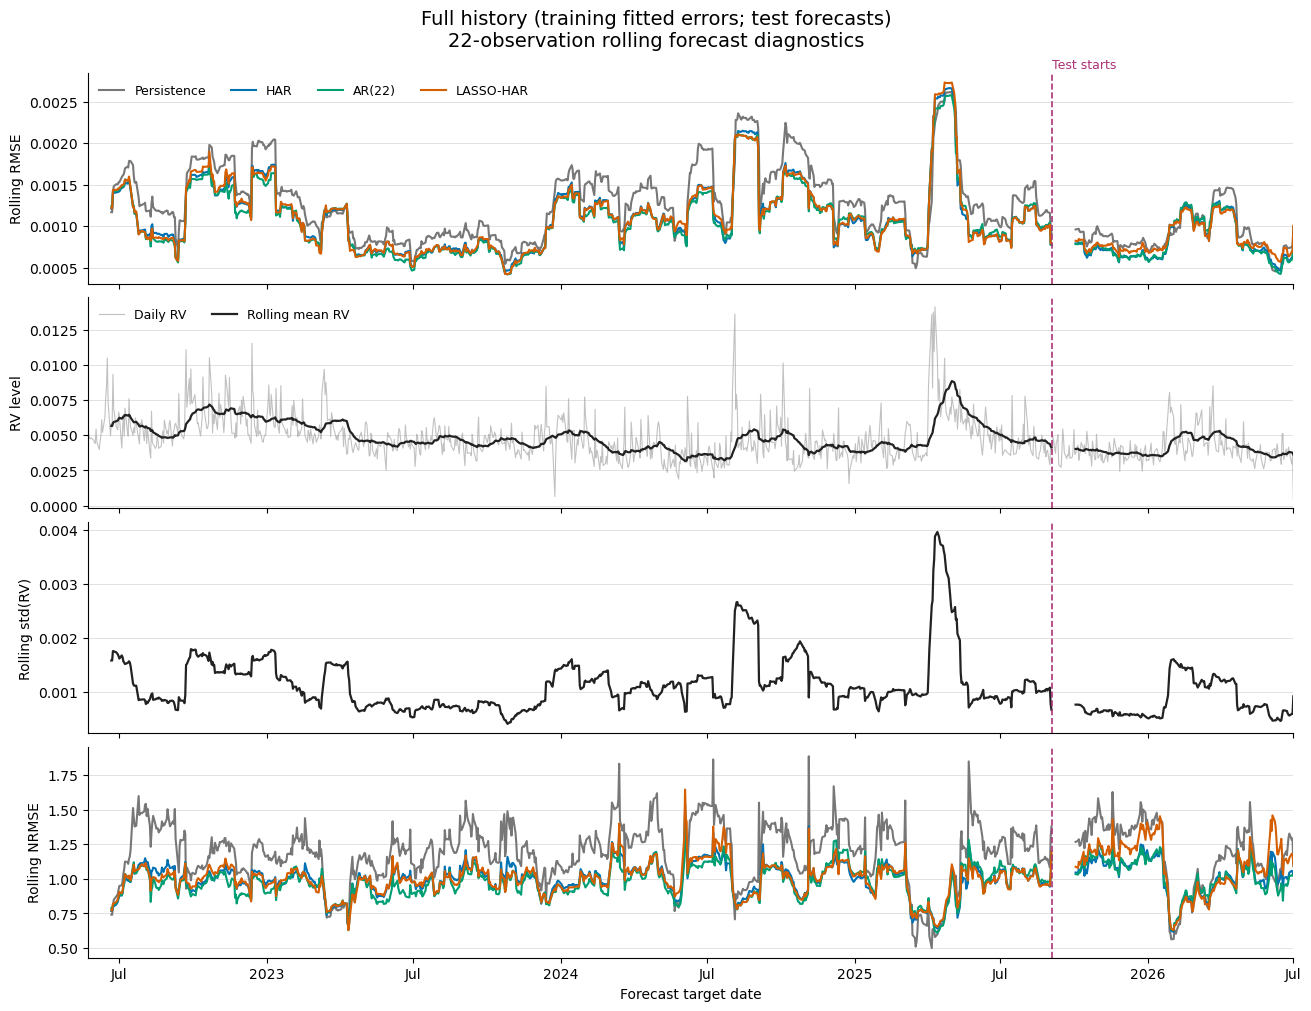

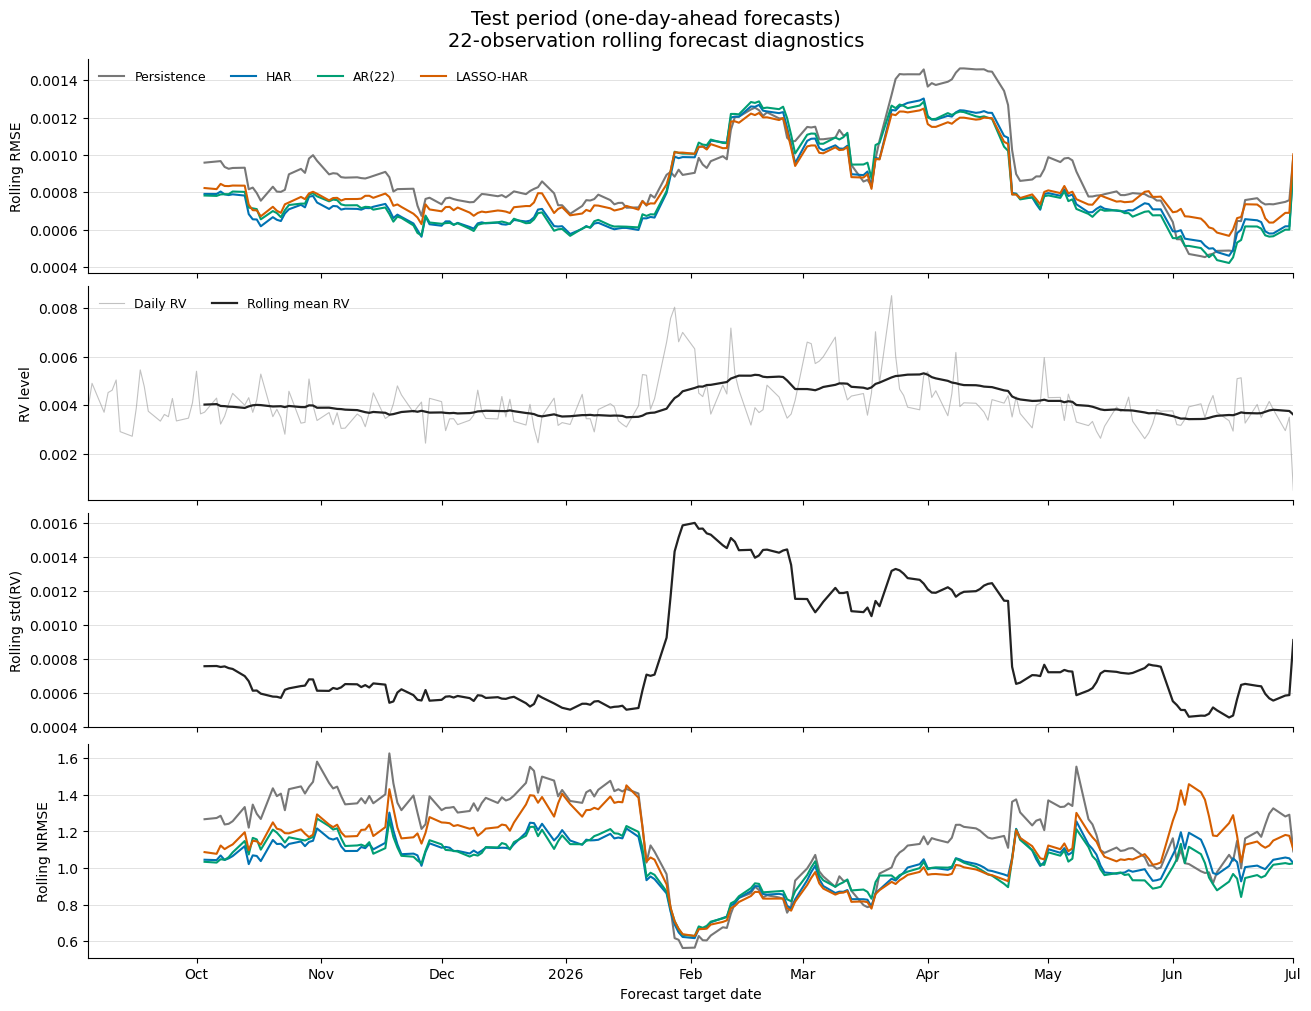

In [16]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

figure_dir = Path(
    r"C:\Users\maria\Project\HAR-RV\figures"
)
figure_dir.mkdir(parents=True, exist_ok=True)

model_colors = {
    "Persistence": "#777777",
    "HAR": "#0072B2",
    "AR(22)": "#009E73",
    "LASSO-HAR": "#D55E00"
}
first_test_date = forecast_history.index[forecast_history["Sample"].eq("Test")][0]
diagnostic_figures = {}

for view_name, view_label, dates in [
    ("full", "Full history (training fitted errors; test forecasts)", forecast_history.index),
    ("test", "Test period (one-day-ahead forecasts)", forecast_history.index[forecast_history["Sample"].eq("Test")])
]:
    fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True, layout="constrained")
    fig.suptitle(
        f"{view_label}\n{rolling_window}-observation rolling forecast diagnostics",
        fontsize=14
    )

    for model_name in model_names:
        axes[0].plot(dates, rolling_rmse.loc[dates, model_name],
                     label=model_name, color=model_colors[model_name], linewidth=1.5)
        axes[3].plot(dates, rolling_nrmse.loc[dates, model_name],
                     color=model_colors[model_name], linewidth=1.5)
    axes[0].set_ylabel("Rolling RMSE")
    axes[0].legend(ncol=4, loc="upper left", frameon=False, fontsize=9)

    axes[1].plot(dates, rolling_rv.loc[dates, "RV_actual"],
                 color="#999999", alpha=0.6, linewidth=0.8, label="Daily RV")
    axes[1].plot(dates, rolling_rv.loc[dates, "RV_mean"],
                 color="#222222", linewidth=1.6, label="Rolling mean RV")
    axes[1].set_ylabel("RV level")
    axes[1].legend(ncol=2, loc="upper left", frameon=False, fontsize=9)

    axes[2].plot(dates, rolling_rv.loc[dates, "RV_std"],
                 color="#222222", linewidth=1.6)
    axes[2].set_ylabel("Rolling std(RV)")
    axes[3].set_ylabel("Rolling NRMSE")
    axes[3].set_xlabel("Forecast target date")

    for ax in axes:
        ax.grid(axis="y", color="#dddddd", linewidth=0.6)
        ax.spines[["top", "right"]].set_visible(False)
        ax.margins(x=0)
        if view_name == "full":
            ax.axvline(first_test_date, color="#AA3377", linestyle="--", linewidth=1.2)
    if view_name == "full":
        axes[0].text(first_test_date, 1.02, "Test starts",
                     transform=axes[0].get_xaxis_transform(), color="#AA3377", fontsize=9)

    if view_name == "full":
        date_locator = mdates.MonthLocator(bymonth=[1, 7])
    else:
        date_locator = mdates.MonthLocator()
    axes[-1].xaxis.set_major_locator(date_locator)
    axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(date_locator))
    diagnostic_figures[view_name] = fig
    fig.savefig(figure_dir / f"rolling_forecast_diagnostics_{view_name}.png", dpi=160)
    fig.savefig(figure_dir / f"rolling_forecast_diagnostics_{view_name}.pdf")
    plt.show()